In [3]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper
# assert version of rectanglepy

# Figure 2

In [5]:
annotations = pd.read_csv('../data/haoSub_annotations.csv', index_col=0)
genes = pd.read_csv('../data/haoSub_genes.csv', index_col=0)
counts = mmread('../data/haoSub_counts.mtx')
counts = pd.DataFrame(counts.todense())
counts = counts.T
counts.columns = genes['x']

In [6]:
adata_hao_sub = AnnData(counts, obs=annotations)

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [7]:
# write adata to file
adata_hao_sub.write_h5ad('../data/haoSub_adata.h5ad')

In [4]:
adata_hao_sub = anndata.read_h5ad('../data/haoSub_adata.h5ad')

In [3]:
sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

## Figure 2A

In [5]:
# Load Bulks
bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/fig2/finotello/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)
bulks_morandini = pd.read_csv("../data/fig2/morandini/morandini_tpm.csv.gz", index_col=0)
bulks_altman = pd.read_csv("../data/fig2/altman/altman_tpm.csv.gz", index_col=0)



In [ ]:
estimations_fino, signature_results_fino = rp.rectangle(adata_hao_sub, bulks_fino.T)


In [7]:
estimations_fino.to_csv("../output/hao_estimations_fino_sub.csv")

In [23]:
estimations_fino = pd.read_csv("../output/hao_estimations_fino_sub.csv", index_col=0)

In [24]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T

<Axes: title={'center': 'Finotello'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

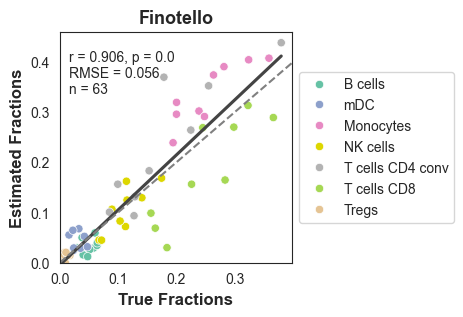

In [25]:
gld_m, finotello_m = helper.match_dfs(finotello_gld, estimations_fino.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
finotello_m = finotello_m.sort_index(key=lambda x: x.str.lower())
evaluation_fintotello_rectangle = helper.create_evaluation_df(gld_m, finotello_m)
rsme_finotello_rectangle, r_finotello_rectangle, p_finotello_rectangle = helper.evaulate_total_df(
    evaluation_fintotello_rectangle)
rsmes_f_rectangle, ps_f_rectangle, rs_f_rectangle = helper.evaluate_by_cell_type(gld_m, finotello_m)
helper.create_scatter_plot_total(evaluation_fintotello_rectangle, rsme_finotello_rectangle, p_finotello_rectangle,
                                 r_finotello_rectangle,
                                 'Finotello', save_path='../figures/fig2a_fino.pdf', size=(3, 3))

In [ ]:
estimations_hoek, signature_results_hoek = rp.rectangle(adata_hao_sub, bulks_hoek.T)
estimations_hoek.to_csv("../output/hao_estimations_hoek_sub.csv")

In [29]:
estimations_hoek = pd.read_csv("../output/hao_estimations_hoek_sub.csv", index_col=0)

<Axes: title={'center': 'Hoek'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

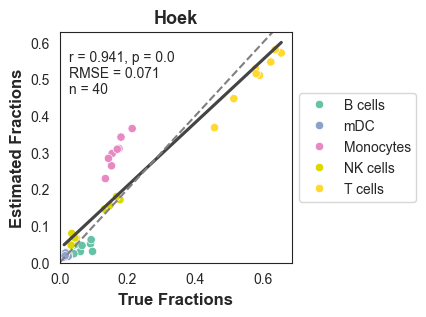

In [30]:
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T


estimations_hoek['T cells'] = estimations_hoek['T cells CD4 conv'] + estimations_hoek['T cells CD8'] + estimations_hoek[
    'Tregs']

estimations_hoek = estimations_hoek.T

gld_hoek_m, hoek_m = helper.match_dfs(hoek_gld, estimations_hoek)
gld_hoek_m = gld_hoek_m.sort_index(key=lambda x: x.str.lower())
hoek_m = hoek_m.sort_index(key=lambda x: x.str.lower())
evaluation_hoek = helper.create_evaluation_df(gld_hoek_m, hoek_m)
rsme_hoek, r_hoek, p_hoek = helper.evaulate_total_df(evaluation_hoek)
rsmes_h, ps_h, rs_h = helper.evaluate_by_cell_type(gld_hoek_m, hoek_m)
helper.create_scatter_plot_total(evaluation_hoek, rsme_hoek, p_hoek, r_hoek, 'Hoek', save_path='../figures/fig2a_hoek.pdf', size=(3, 3))

In [ ]:
estimations_chen, signatures_chen  = rp.rectangle(adata_muris, bulks_chen.T)
estimations_chen.to_csv("../output/muris_estimations_chen.csv")

In [31]:
estimations_chen= pd.read_csv("../output/muris_estimations_chen.csv", index_col=0)

<Axes: title={'center': 'Chen'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

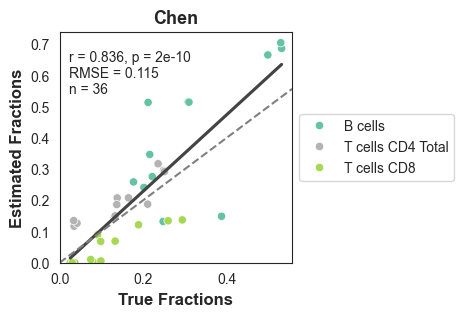

In [33]:
chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
chen_t = estimations_chen
chen_t['T cells CD4 Total'] = chen_t['T cells CD4 conv'] + chen_t['Tregs']
chen_m, gld_m = helper.match_dfs(chen_t,chen_gld)
# sort alphabetically reverse
gld_m = gld_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
chen_m = chen_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
evaluation_chen = helper.create_evaluation_df(gld_m.T, chen_m.T)
# sort by index alphabetically ignore case
evaluation_chen = evaluation_chen.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_chen, r_chen, p_chen = helper.evaulate_total_df(evaluation_chen)
rsmes_chen, ps_chen, rs_chen = helper.evaluate_by_cell_type(gld_m.T, chen_m.T)

helper.create_scatter_plot_total(evaluation_chen, rsme_chen, p_chen, r_chen, 'Chen', save_path='../figures/fig2a_chen.pdf', size=(3, 3))

In [ ]:
estimations_peti, signatures_peti = rp.rectangle(adata_muris, bulks_peti.T)
estimations_peti.to_csv('../output/muris_estimations_peti.csv')

In [34]:
estimations_peti = pd.read_csv('../output/muris_estimations_peti.csv', index_col=0)

<Axes: title={'center': 'Petitprez'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

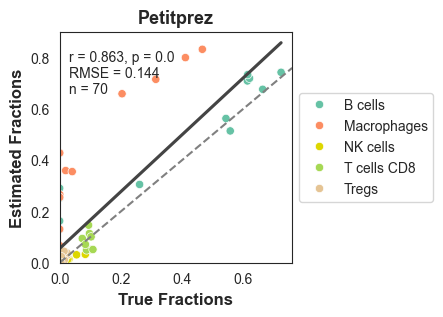

In [35]:
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)

# replace nan with 0
petitprez_gld = petitprez_gld.fillna(0)

petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
# drop columns
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

# sort by index alphabetically ignore case
petitprez_gld = petitprez_gld.sort_index(key=lambda x: x.str.lower())
estimations_peti = estimations_peti.sort_index(key=lambda x: x.str.lower())


gld_m, petitprez_m = helper.match_dfs(petitprez_gld, estimations_peti)
evaluation_petitprez = helper.create_evaluation_df(gld_m.T, petitprez_m.T)
# sort by index alphabetically ignore case
evaluation_petitprez = evaluation_petitprez.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_peptirez, r_peptirez, p_peptirez = helper.evaulate_total_df(evaluation_petitprez)
rsmes_pept, ps_pept, rs_pept = helper.evaluate_by_cell_type(gld_m.T, petitprez_m.T)

helper.create_scatter_plot_total(evaluation_petitprez, rsme_peptirez, p_peptirez, r_peptirez, 'Petitprez',
                                 save_path='../figures/fig2a_petitprez.pdf', size=(3, 3))


In [ ]:
estimations_morandini, signatures_morandini = rp.rectangle(adata_hao_sub, bulks_morandini.T)


In [35]:
estimations_morandini.to_csv('../output/hao_estimations_morandini.csv')

In [36]:
estimations_morandini = pd.read_csv('../output/hao_estimations_morandini.csv', index_col=0).T
estimations_morandini['T cells CD4'] = estimations_morandini['T cells CD4 conv']
estimations_morandini['T cells'] = estimations_morandini['T cells CD4 conv'] + estimations_morandini['T cells CD8'] + estimations_morandini[
    'Tregs']
estimations_morandini['Lymphocytes'] = estimations_morandini['T cells'] + estimations_morandini['NK cells'] + estimations_morandini['ILC'] + estimations_morandini['B cells'] + estimations_morandini['Plasma cells']
estimations_morandini['Monocytes'] = estimations_morandini['Monocytes'] + estimations_morandini['pDC'] + estimations_morandini['mDC']
estimations_morandini = estimations_morandini.T

In [37]:
morandini_facs = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
morandini_facs = morandini_facs.T



In [38]:
gld_m, morandini_m = helper.match_dfs(morandini_facs.T, estimations_morandini)

<Axes: title={'center': 'Morandini'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

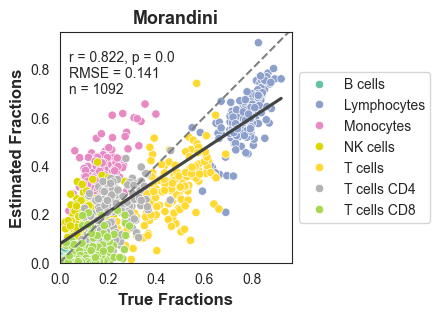

In [39]:

gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
morandini_m = morandini_m.sort_index(key=lambda x: x.str.lower())
evaluation_morandini = helper.create_evaluation_df(gld_m, morandini_m)
rsme_morandini, r_morandini, p_morandini = helper.evaulate_total_df(evaluation_morandini)
rsmes_morandini, ps_morandini, rs_morandini = helper.evaluate_by_cell_type(gld_m, morandini_m)
helper.create_scatter_plot_total(evaluation_morandini, rsme_morandini, p_morandini, r_morandini,
                                 'Morandini', save_path='../figures/fig2a_morandini.pdf', size=(3, 3))

In [ ]:
estimations_altman, signatures_altman = rp.rectangle(adata_hao_sub, bulks_altman.T)

In [41]:
estimations_altman = pd.read_csv('../output/hao_estimations_altman.csv', index_col=0)

estimations_altman['Lymphocytes'] = estimations_altman['T cells CD4 conv'] + estimations_altman['T cells CD8'] + estimations_altman[
    'Tregs'] + estimations_altman['B cells'] + estimations_altman['NK cells'] + estimations_altman['ILC']
estimations_altman['Plasma cells'] = estimations_altman['Lymphocytes'] + estimations_altman['Plasma cells']
estimations_altman['Monocytes'] = estimations_altman['Monocytes'] + estimations_altman['mDC'] + estimations_altman['pDC']
estimations_altman = estimations_altman.T

In [42]:
altman_facs = pd.read_csv('../data/fig2/altman/altman_facs.csv', index_col=0)
altman_facs = altman_facs.T

In [43]:
gld_m, altman_m = helper.match_dfs(altman_facs.T, estimations_altman)

<Axes: title={'center': 'Altman'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

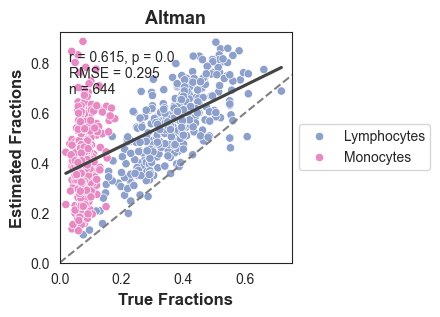

In [44]:
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
altman_m = altman_m.sort_index(key=lambda x: x.str.lower())
evaluation_altman = helper.create_evaluation_df(gld_m, altman_m)
rsme_altman, r_altman, p_altman = helper.evaulate_total_df(evaluation_altman)
rsmes_altman, ps_altman, rs_altman = helper.evaluate_by_cell_type(gld_m, altman_m)
helper.create_scatter_plot_total(evaluation_altman, rsme_altman, p_altman, r_altman,
                                 'Altman', save_path='../figures/fig2a_altman.pdf', size=(3, 3))

# Figure 2B

In [46]:
corr_df_fino = pd.DataFrame(index=finotello_m.index, data=rs_f_rectangle)
corr_df_pept = pd.DataFrame(index=petitprez_m.T.index, data=rs_pept)
corr_df_chen = pd.DataFrame(index=chen_m.T.index, data=rs_chen)
corr_df_hoek = pd.DataFrame(index=hoek_m.index, data=rs_h)
corr_df_morandini = pd.DataFrame(index=morandini_m.index, data=rs_morandini)
corr_df_altman = pd.DataFrame(index=altman_m.index, data=rs_altman)

rmse_df_fino = pd.DataFrame(index=finotello_m.index, data=rsmes_f_rectangle)
rmse_df_pept = pd.DataFrame(index=petitprez_m.T.index, data=rsmes_pept)
rmse_df_chen = pd.DataFrame(index=chen_m.T.index, data=rsmes_chen)
rmse_df_hoek = pd.DataFrame(index=hoek_m.index, data=rsmes_h)

rmse_df_morandini = pd.DataFrame(index=morandini_m.index, data=rsmes_morandini)
rmse_df_altman = pd.DataFrame(index=altman_m.index, data=rsmes_altman)


<Figure size 640x480 with 0 Axes>

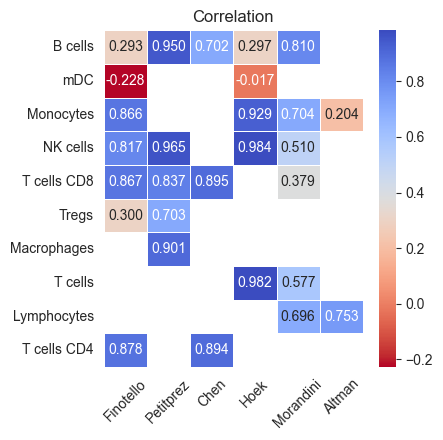

In [50]:
df_cor = pd.concat([corr_df_fino, corr_df_pept, corr_df_chen, corr_df_hoek, corr_df_morandini, corr_df_altman], axis=1)
df_cor.columns = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Altman']
df_cor = df_cor.T
df_cor['T cells CD4'] = df_cor['T cells CD4 Total'].add(df_cor['T cells CD4 conv'], fill_value=0)
df_cor = df_cor.drop(columns=['T cells CD4 Total', 'T cells CD4 conv'])
plt.figure(facecolor='white')
# size
plt.figure(figsize=(4.5, 4.5))
# Plot the first heatmap
import seaborn as sns
sns.set_style("white")
sns.heatmap(df_cor.T, annot=True, cmap='coolwarm_r', fmt=".3f", linewidths=.5)
plt.title('Correlation')
#rotating the x-axis labels
plt.xticks(rotation=45)


# Adjust spacing between subplots
plt.tight_layout()

plt.savefig('../figures/fig2b_corr_heat.pdf')

# Display the subplots
plt.show()



<Figure size 640x480 with 0 Axes>

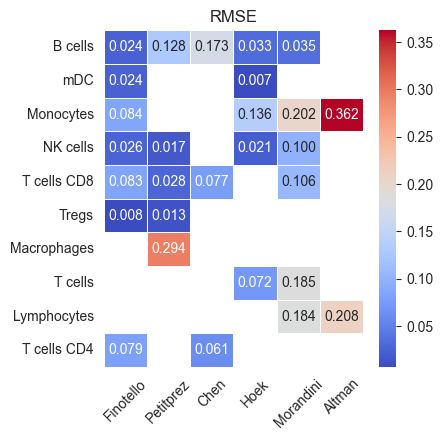

In [52]:
df_rmse = pd.concat([rmse_df_fino, rmse_df_pept, rmse_df_chen, rmse_df_hoek, rmse_df_morandini, rmse_df_altman], axis=1)
df_rmse.columns = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Altman']
df_rmse = df_rmse.T
df_rmse['T cells CD4'] = df_rmse['T cells CD4 Total'].add(df_rmse['T cells CD4 conv'], fill_value=0)
df_rmse = df_rmse.drop(columns=['T cells CD4 Total', 'T cells CD4 conv'])
plt.figure(facecolor='white')
# size
plt.figure(figsize=(4.5, 4.5))
# Plot the first heatma
import seaborn as sns
sns.set_style("white")

sns.heatmap(df_rmse.T, annot=True, cmap='coolwarm', fmt=".3f", linewidths=.5)
plt.title('RMSE')
#rotating the x-axis labels
plt.xticks(rotation=45)


# Adjust spacing between subplots
plt.tight_layout()

plt.savefig('../figures/fig2b_rmse_heat.pdf')

## Fig 2c



In [53]:
all_meths = pd.read_csv('../data/cor_rmse_all.csv', sep=';')
# replace ',' with '.'
all_meths['Correlation'] = all_meths['Cor'].str.replace(',', '.').astype(float)
all_meths['RMSE'] = all_meths['RMSE'].str.replace(',', '.').astype(float)

all_meths_chen = all_meths[all_meths['Set'] == 'Chen']
all_meths_fino = all_meths[all_meths['Set'] == 'Finotello']
all_meths_hoek = all_meths[all_meths['Set'] == 'Hoek']
all_meths_peti = all_meths[all_meths['Set'] == 'Petitprez']
all_meths_morandini = all_meths[all_meths['Set'] == 'Morandini']
all_meths_altman = all_meths[all_meths['Set'] == 'Altman']

In [54]:
method_palette = {
    "autogenes": "#66C2A5",
    "bayesprism": "#FC8D62",
    "bisque": "#8DA0CB",
    "cibersortx": "#E78AC3",
    "dwls": "#A6D854",
    "music": "#FFD92F",
    "scaden": "#E5C494",
    "scdc": "#B3B3B3",
    "rectangle": "#000000"
}

color_palette = [method_palette[key] for key in method_palette]

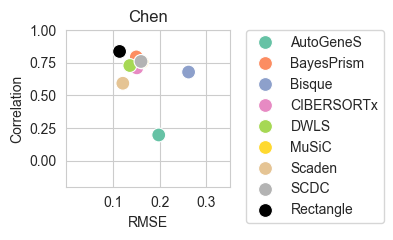

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# style white with ticks
sns.set_style("whitegrid")


plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_chen, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Chen')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

plt.tight_layout()
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)
#include ticks
# move the legend
#horizantal legend
#tight layout

plt.savefig('../figures/fig2c_chen.pdf')
plt.show()

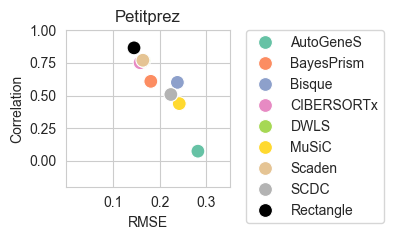

In [23]:
sns.set_style("whitegrid")


plt.figure(figsize=(2.5, 2.5))

sns.scatterplot(data=all_meths_peti, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Petitprez')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

# set y axis limits
plt.tight_layout()
# move the legend
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)#tight layout
plt.savefig('../figures/fig2c_petitprez.pdf')
plt.show()

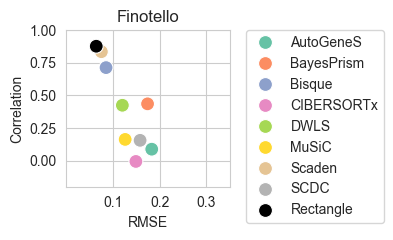

In [25]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_fino, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Finotello')
plt.ylim(-0.20, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

plt.tight_layout()

plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)

plt.savefig('../figures/fig2c_fino.pdf')
plt.show()

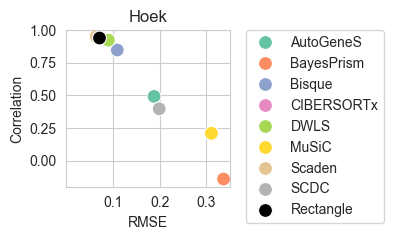

In [26]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_hoek, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Hoek')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
# some more x ticks
plt.xticks([0.1, 0.2, 0.3])

#legend title
plt.tight_layout()

# move the legend
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)
#tight layout
plt.savefig('../figures/fig2c_hoek.pdf')
plt.show()


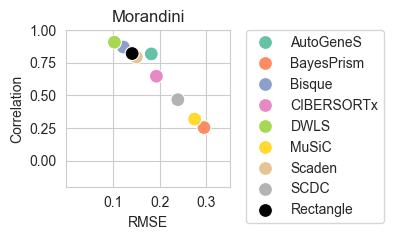

In [66]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_morandini, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Morandini')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

plt.tight_layout()
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)#tight layout
plt.savefig('../figures/fig2c_morandini.pdf')
plt.show()

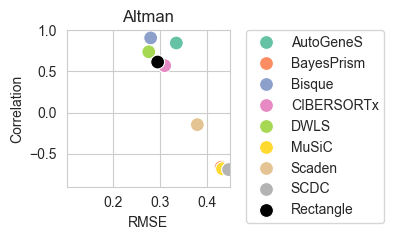

In [76]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_altman, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Altman')
plt.ylim(-0.9, 1)
plt.xlim(0.1, 0.45)
plt.xticks([0.2, 0.3, 0.4])
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)#tight layout
plt.savefig('../figures/fig2c_altman.pdf')
plt.show()